# AML 03 — Floor Classification

**Objective.** Predict FLOOR from Member 1's Wi-Fi feature table. This notebook uses the documented shared split without changing preprocessing: it tunes only on the internal validation split, then evaluates its frozen configuration once on the supplied held-out validation split.

The floor codes are reused across buildings, so this is a floor-only task rather than a combined building-floor classifier. BUILDINGID, all targets, and collection identifiers are excluded from predictors.

In [1]:
from pathlib import Path
import platform
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

print(f'Python: {platform.python_version()} ({sys.executable})')
print(f'NumPy: {np.__version__}; pandas: {pd.__version__}; scikit-learn: {sklearn.__version__}')
print(f'Matplotlib: {plt.matplotlib.__version__}; seaborn: {sns.__version__}')

RANDOM_STATE = 42
N_JOBS = -1

def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if ((parent / 'data/processed/aml_internal_train_features.csv').is_file()
                and (parent / 'Machine Learning Pipeline').is_dir()):
            return parent
    raise FileNotFoundError('Could not locate the repository root from the current working directory')

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
TRAIN_PATH = PROCESSED_DIR / 'aml_internal_train_features.csv'
INTERNAL_VAL_PATH = PROCESSED_DIR / 'aml_internal_validation_features.csv'
HELDOUT_PATH = PROCESSED_DIR / 'aml_heldout_validation_features.csv'
print('Repository root:', PROJECT_ROOT)
print('Inputs:', *(path.relative_to(PROJECT_ROOT) for path in [TRAIN_PATH, INTERNAL_VAL_PATH, HELDOUT_PATH]), sep='\n  - ')

Python: 3.13.6 (/Library/Frameworks/Python.framework/Versions/3.13/bin/python3.13)
NumPy: 2.5.2; pandas: 3.0.5; scikit-learn: 1.9.0
Matplotlib: 3.11.1; seaborn: 0.13.2
Repository root: /Users/gargisrivastava/Documents/Signal2Space
Inputs:
  - data/processed/aml_internal_train_features.csv
  - data/processed/aml_internal_validation_features.csv
  - data/processed/aml_heldout_validation_features.csv


## 1. Load Member 1's development splits

The internal-training and internal-validation artifacts are read first. The held-out artifact is intentionally not read until after the configuration is frozen.

In [2]:
assert TRAIN_PATH.is_file() and INTERNAL_VAL_PATH.is_file() and HELDOUT_PATH.is_file()
internal_train = pd.read_csv(TRAIN_PATH)
internal_validation = pd.read_csv(INTERNAL_VAL_PATH)

print('internal_train:', internal_train.shape)
print('internal_validation:', internal_validation.shape)
print('Source partitions:', internal_train['SOURCE_PARTITION'].unique().tolist(), internal_validation['SOURCE_PARTITION'].unique().tolist())

internal_train: (16085, 1057)
internal_validation: (3852, 1057)
Source partitions: ['trainingData'] ['trainingData']


## 2. Schema, feature allowlist, and target checks

Member 1's FEATURE_COLUMNS contract is reconstructed from actual columns: 520 scaled RSSI features, 520 observed-signal indicators, and six row summaries. No target, location metadata, or identifier is used as a predictor. The grouped development split is preserved: 80% of trainingData.csv for internal training and 20% for internal validation, grouped by (BUILDINGID, FLOOR, SPACEID) with seed 42.

In [3]:
TARGET_COLUMNS = ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']
IDENTIFIER_COLUMNS = ['ROW_ID', 'SOURCE_PARTITION', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']
FLOOR_TARGET = 'FLOOR'
SUMMARY_COLUMNS = ['n_heard', 'max_rssi_dbm', 'mean_rssi_dbm', 'std_rssi_dbm', 'n_strong', 'top1_ap_index']
RSSI_COLUMNS = [column for column in internal_train.columns if column.startswith('RSSI_Z__WAP')]
SEEN_COLUMNS = [column for column in internal_train.columns if column.startswith('SEEN__WAP')]
FEATURE_COLUMNS = RSSI_COLUMNS + SEEN_COLUMNS + SUMMARY_COLUMNS

if len(RSSI_COLUMNS) != 520 or len(SEEN_COLUMNS) != 520:
    raise ValueError(f'Expected 520 RSSI and 520 indicator columns, found {len(RSSI_COLUMNS)} and {len(SEEN_COLUMNS)}')
if internal_train.columns.tolist() != internal_validation.columns.tolist():
    raise ValueError('Internal split schemas differ in column order')
if set(FEATURE_COLUMNS) & set(TARGET_COLUMNS + IDENTIFIER_COLUMNS):
    raise ValueError('Predictor allowlist contains a target or identifier')
if internal_train[FEATURE_COLUMNS].isna().any().any() or internal_validation[FEATURE_COLUMNS].isna().any().any():
    raise ValueError('Member 1 feature tables contain missing model inputs')
if not np.isfinite(internal_train[FEATURE_COLUMNS].to_numpy(dtype=np.float32)).all():
    raise ValueError('Internal-training features contain non-finite values')
if not np.isfinite(internal_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)).all():
    raise ValueError('Internal-validation features contain non-finite values')
if set(internal_train['ROW_ID']) & set(internal_validation['ROW_ID']):
    raise ValueError('ROW_ID overlap found between internal development splits')
if set(internal_train['SOURCE_PARTITION']) != {'trainingData'} or set(internal_validation['SOURCE_PARTITION']) != {'trainingData'}:
    raise ValueError('Internal splits must both come from trainingData')

print('Predictors:', len(FEATURE_COLUMNS), f'({len(RSSI_COLUMNS)} RSSI + {len(SEEN_COLUMNS)} indicators + {len(SUMMARY_COLUMNS)} summaries)')
print('Train floor distribution:', internal_train[FLOOR_TARGET].value_counts().sort_index().to_dict())
print('Internal-validation floor distribution:', internal_validation[FLOOR_TARGET].value_counts().sort_index().to_dict())
print('Floors by building (training):', internal_train.groupby('BUILDINGID')[FLOOR_TARGET].unique().apply(lambda values: sorted(values.tolist())).to_dict())

Predictors: 1046 (520 RSSI + 520 indicators + 6 summaries)
Train floor distribution: {0: 3569, 1: 3892, 2: 3592, 3: 4170, 4: 862}
Internal-validation floor distribution: {0: 800, 1: 1110, 2: 824, 3: 878, 4: 240}
Floors by building (training): {0: [0, 1, 2, 3], 1: [0, 1, 2, 3], 2: [0, 1, 2, 3, 4]}


## 3. Floor-label mapping and model choice

RandomForestClassifier is appropriate for the high-dimensional, nonlinear Wi-Fi tabular features and is already available through the shared scikit-learn dependency. The mapping is fitted **only** from internal-training labels in ascending numeric order, then reused for every validation and held-out operation. This makes label handling explicit even though Random Forest can natively consume integer class labels.

In [4]:
FLOOR_CLASSES = np.sort(internal_train[FLOOR_TARGET].unique()).astype(int)
FLOOR_TO_CLASS_ID = {int(floor): int(index) for index, floor in enumerate(FLOOR_CLASSES)}
CLASS_ID_TO_FLOOR = {class_id: floor for floor, class_id in FLOOR_TO_CLASS_ID.items()}

def encode_floors(labels, split_name):
    labels = pd.Series(labels)
    unknown = sorted(set(labels.unique()) - set(FLOOR_TO_CLASS_ID))
    if unknown:
        raise ValueError(f'{split_name} contains floor labels unseen in internal training: {unknown}')
    return labels.map(FLOOR_TO_CLASS_ID).to_numpy(dtype=np.int64)

def decode_floors(class_ids):
    class_ids = np.asarray(class_ids, dtype=np.int64)
    if not set(class_ids).issubset(CLASS_ID_TO_FLOOR):
        raise ValueError('Prediction contains an unknown encoded floor class')
    return np.asarray([CLASS_ID_TO_FLOOR[class_id] for class_id in class_ids])

y_train = encode_floors(internal_train[FLOOR_TARGET], 'internal training')
y_internal_val = encode_floors(internal_validation[FLOOR_TARGET], 'internal validation')
X_train = internal_train[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
X_internal_val = internal_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

print('Verified floor labels:', FLOOR_CLASSES.tolist())
print('Training-only mapping:', FLOOR_TO_CLASS_ID)
print('Feature/target shapes:', X_train.shape, y_train.shape, X_internal_val.shape, y_internal_val.shape)

Verified floor labels: [0, 1, 2, 3, 4]
Training-only mapping: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4}
Feature/target shapes: (16085, 1046) (16085,) (3852, 1046) (3852,)


## 4. Baseline and internal-validation tuning

Accuracy is the selection metric because the assignment requires floor accuracy; macro F1 is reported as a class-balanced diagnostic. Every candidate is fitted on the shared internal-training split and scored only on the shared internal-validation split. The compact grid varies tree count, depth, and leaf size while keeping class_weight='balanced' to reduce the influence of the rarer floor 4. Ties are resolved deterministically by higher macro F1, then fewer trees, shallower depth, and larger leaves.

In [5]:
def make_model(params):
    return RandomForestClassifier(
        **params,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )

BASELINE_PARAMS = {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
baseline_model = make_model(BASELINE_PARAMS)
t0 = time.perf_counter()
baseline_model.fit(X_train, y_train)
baseline_seconds = time.perf_counter() - t0
baseline_pred = baseline_model.predict(X_internal_val)
baseline_accuracy = accuracy_score(y_internal_val, baseline_pred)
baseline_macro_f1 = f1_score(y_internal_val, baseline_pred, average='macro', zero_division=0)
print(f'Baseline internal-validation accuracy: {baseline_accuracy:.4f}; macro F1: {baseline_macro_f1:.4f}; fit time: {baseline_seconds:.1f}s')

PARAM_GRID = [
    {'n_estimators': n_estimators, 'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf, 'max_features': 'sqrt'}
    for n_estimators in (150, 300)
    for max_depth in (None, 30)
    for min_samples_leaf in (1, 2)
]
print('Tuning candidates:', len(PARAM_GRID))

tuning_rows = []
for params in PARAM_GRID:
    model = make_model(params)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - t0
    predictions = model.predict(X_internal_val)
    tuning_rows.append({
        **params,
        'internal_validation_accuracy': accuracy_score(y_internal_val, predictions),
        'internal_validation_macro_f1': f1_score(y_internal_val, predictions, average='macro', zero_division=0),
        'fit_seconds': fit_seconds,
    })

tuning_results = pd.DataFrame(tuning_rows)
tuning_results['depth_sort'] = tuning_results['max_depth'].fillna(np.inf)
tuning_results = tuning_results.sort_values(
    ['internal_validation_accuracy', 'internal_validation_macro_f1', 'n_estimators', 'depth_sort', 'min_samples_leaf'],
    ascending=[False, False, True, True, False],
    ignore_index=True,
).drop(columns='depth_sort')
display(tuning_results)

Baseline internal-validation accuracy: 0.9621; macro F1: 0.9658; fit time: 0.5s
Tuning candidates: 8


,n_estimators,max_depth,min_samples_leaf,max_features,internal_validation_accuracy,internal_validation_macro_f1,fit_seconds
0,150,NaN,1,sqrt,0.964174,0.967825,0.653139
1,300,NaN,1,sqrt,0.963655,0.967385,1.275946
2,300,30.0,1,sqrt,0.958463,0.962873,1.230481
3,300,NaN,2,sqrt,0.958463,0.962851,1.237813
4,150,NaN,2,sqrt,0.954829,0.959849,0.639689
5,150,30.0,1,sqrt,0.954050,0.959500,0.593762
6,150,30.0,2,sqrt,0.953011,0.957719,0.578677
7,300,30.0,2,sqrt,0.950415,0.955998,1.168520


## 5. Freeze the selected configuration

The selected configuration below is derived solely from the internal-validation table above. The held-out CSV has not yet been read, and no result below changes the model family, predictors, label mapping, or hyperparameters.

In [6]:
best_row = tuning_results.iloc[0]
BEST_PARAMS = {
    'n_estimators': int(best_row['n_estimators']),
    'max_depth': None if pd.isna(best_row['max_depth']) else int(best_row['max_depth']),
    'min_samples_leaf': int(best_row['min_samples_leaf']),
    'max_features': best_row['max_features'],
}
print('Frozen configuration:', BEST_PARAMS)
print(f"Internal-validation accuracy used for selection: {best_row['internal_validation_accuracy']:.4f}")

final_model = make_model(BEST_PARAMS)
t0 = time.perf_counter()
final_model.fit(X_train, y_train)
final_fit_seconds = time.perf_counter() - t0
print(f'Final model fitted on internal training only in {final_fit_seconds:.1f}s')

Frozen configuration: {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Internal-validation accuracy used for selection: 0.9642


Final model fitted on internal training only in 0.7s


## 6. Final held-out evaluation

This is the first held-out-data read in this notebook. Its schema is checked against the internal-training table before the frozen model makes predictions.

In [7]:
heldout_validation = pd.read_csv(HELDOUT_PATH)
if heldout_validation.columns.tolist() != internal_train.columns.tolist():
    raise ValueError('Held-out schema differs from internal-training schema')
if heldout_validation[FEATURE_COLUMNS].isna().any().any():
    raise ValueError('Held-out table contains missing model inputs')
if not np.isfinite(heldout_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)).all():
    raise ValueError('Held-out features contain non-finite values')
if set(heldout_validation['SOURCE_PARTITION']) != {'validationData'}:
    raise ValueError('Held-out rows must come from validationData')

X_heldout = heldout_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_heldout = encode_floors(heldout_validation[FLOOR_TARGET], 'held-out validation')
heldout_pred_encoded = final_model.predict(X_heldout)
heldout_pred = decode_floors(heldout_pred_encoded)
y_heldout_labels = heldout_validation[FLOOR_TARGET].to_numpy()

if not set(heldout_pred).issubset(set(FLOOR_CLASSES)):
    raise ValueError('Held-out predictions include a floor unseen in internal training')
heldout_accuracy = accuracy_score(y_heldout_labels, heldout_pred)
heldout_macro_f1 = f1_score(y_heldout, heldout_pred_encoded, average='macro', zero_division=0)
print('Held-out rows:', len(heldout_validation))
print(f'Held-out floor accuracy: {heldout_accuracy:.4f}')
print(f'Held-out macro F1: {heldout_macro_f1:.4f}')

Held-out rows: 1111
Held-out floor accuracy: 0.8893
Held-out macro F1: 0.8727


## 7. Held-out floor confusion matrix

Rows are true floor labels and columns are predictions. The matrix uses the explicit training-derived order FLOOR_CLASSES; an absent class would therefore remain visible as an all-zero row or column. Values are counts, not rates.

Predicted floor,0,1,2,3,4
True floor,,,,,
0,119,9,4,0,0
1,11,401,49,1,0
2,0,8,279,19,0
3,0,0,8,162,2
4,1,1,0,10,27


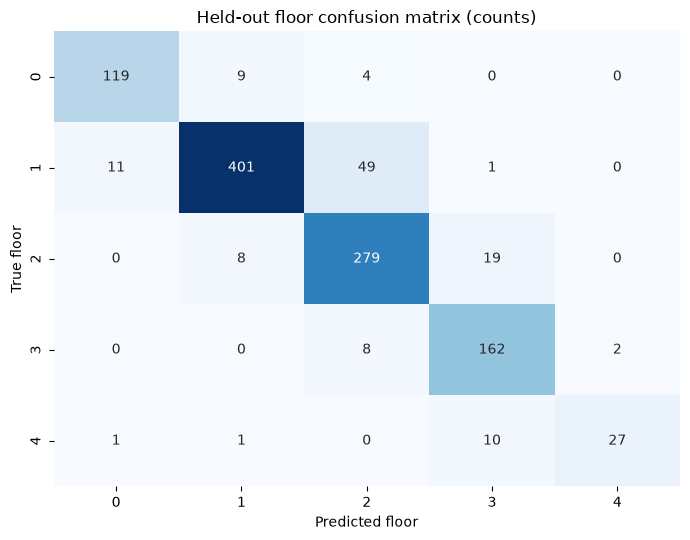

In [8]:
heldout_confusion_counts = confusion_matrix(y_heldout_labels, heldout_pred, labels=FLOOR_CLASSES)
if heldout_confusion_counts.shape != (len(FLOOR_CLASSES), len(FLOOR_CLASSES)):
    raise ValueError('Unexpected confusion-matrix dimensions')
if heldout_confusion_counts.sum() != len(heldout_validation):
    raise ValueError('Confusion-matrix counts do not match held-out rows')

confusion_counts_df = pd.DataFrame(
    heldout_confusion_counts,
    index=pd.Index(FLOOR_CLASSES, name='True floor'),
    columns=pd.Index(FLOOR_CLASSES, name='Predicted floor'),
)
display(confusion_counts_df)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(confusion_counts_df, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Held-out floor confusion matrix (counts)')
ax.set_xlabel('Predicted floor')
ax.set_ylabel('True floor')
fig.tight_layout()
plt.show()

## 8. Reproducibility summary and limitations

The final result below is computed from this run. The model uses Member 1's train-only scaled signal features and fixed shared split. It does not use building labels, coordinates, collection metadata, or identifiers. Random Forest training is seeded; minor run-time variation may occur with parallel execution, while predictions should be reproducible for the recorded package versions.

In [9]:
print('=' * 78)
print('FLOOR CLASSIFICATION SUMMARY')
print('=' * 78)
print(f'Shared splits: internal train={len(internal_train):,}; internal validation={len(internal_validation):,}; held-out={len(heldout_validation):,}')
print('Predictors:', len(FEATURE_COLUMNS), '| excluded targets:', TARGET_COLUMNS, '| excluded identifiers:', IDENTIFIER_COLUMNS)
print('Floor labels / encoded IDs:', FLOOR_TO_CLASS_ID)
print('Model: RandomForestClassifier(class_weight=balanced, random_state=42, n_jobs=-1)')
print('Frozen parameters:', BEST_PARAMS)
print(f'Baseline internal-validation accuracy: {baseline_accuracy:.4f}')
print(f"Selected internal-validation accuracy: {best_row['internal_validation_accuracy']:.4f}")
print(f'Held-out floor accuracy: {heldout_accuracy:.4f}')
print(f'Held-out macro F1: {heldout_macro_f1:.4f}')
print('Confusion-matrix label order:', FLOOR_CLASSES.tolist())
print('Python/package versions:', platform.python_version(), np.__version__, pd.__version__, sklearn.__version__)

FLOOR CLASSIFICATION SUMMARY
Shared splits: internal train=16,085; internal validation=3,852; held-out=1,111
Predictors: 1046 | excluded targets: ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE'] | excluded identifiers: ['ROW_ID', 'SOURCE_PARTITION', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']
Floor labels / encoded IDs: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4}
Model: RandomForestClassifier(class_weight=balanced, random_state=42, n_jobs=-1)
Frozen parameters: {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Baseline internal-validation accuracy: 0.9621
Selected internal-validation accuracy: 0.9642
Held-out floor accuracy: 0.8893
Held-out macro F1: 0.8727
Confusion-matrix label order: [0, 1, 2, 3, 4]
Python/package versions: 3.13.6 2.5.2 3.0.5 1.9.0
